# Etapa 3 — co-saliência via spectral clustering global

A Etapa 2 operou em PARES de imagens (grafo 2P × 2P) e devolveu um score
contínuo (`fg_scores`) por votação entre pares. A Etapa 3 muda de escala:
constrói UM grafo com a COLEÇÃO INTEIRA (N·P nós) e agrupa os patches em
clusters globais — estrutura que só emerge quando todas as imagens são
vistas ao mesmo tempo, não par a par.

Roteiro:

1. carregar `features_notebook.npz` (E1) e `correspondence_notebook.npz` (E2);
2. máscara de conteúdo (padding) — mesmo raciocínio da E2, recalculada aqui;
3. escalonamento adaptativo de `n_clusters` quando há padding relevante;
4. grafo global kNN esparso;
5. embedding espectral (autovetores do Laplaciano);
6. k-means espectral;
7. saliência espacial por cluster (centralidade + compacidade);
8. (extra) prior de borda — modo experimental `e2_border_topk`;
9. mapeamento cluster → foreground/background;
10. refinamento NCut intra-imagem (opcional, desativado por padrão);
11. upsample para o tamanho original da imagem;
12. seeds para a Etapa 4 (SAM prompting);
13. salvar `cosaliency_notebook.npz`.

> **⚠️ CLI do script vs. config do pipeline (mesmo padrão das Etapas 1 e 2).**
> `step3_cosaliency.py` tem defaults de CLI mais conservadores/antigos:
> `--n_clusters 5`, `--k_neighbors 10`. `run_pipeline.sh` sobrescreve os dois
> com a config calibrada: `E3_N_CLUSTERS=8`, `E3_K_NEIGHBORS=15`,
> `E3_N_SPECTRAL=8` (igual ao CLI), `E3_SALIENCY_ALPHA=0.5` (igual ao CLI).
> `fg_decision_mode` é `"saliency"` nos dois (o modo alternativo
> `"e2_border_topk"` é experimental e só liga com
> `E3_FG_DECISION_MODE=e2_border_topk` explícito). Mascaramento de padding e
> escalonamento adaptativo de clusters vêm ligados por padrão nos dois.
>
> **Nota sobre a calibração de `nc`/`kn`/`alpha`:** o comentário em
> `run_pipeline.sh` documenta que uma calibração anterior desses mesmos
> parâmetros (`nc=8, kn=10, alpha=0.75`) foi refeita porque estava
> contaminada — usava features/correspondence "melhores por classe" de uma
> rodada anterior, em vez da cadeia E1→E2→E3 com uma config única e
> consistente. Recalibrado do zero com a config real (E1 `vits14/518/
> keep_ar/l2`, E2 `top_k=60/temperature=0.05`), o vencedor mudou para
> `nc=8, kn=15, alpha=0.5` (patch_iou médio 0.563, pior caso 0.394 — contra
> 0.462 médio / 0.000 pior-caso do default antigo `nc=5/kn=10`). Se você
> tinha `nc=8/kn=10/alpha=0.75` anotado como o resultado "confirmado" de uma
> sessão anterior, vale reconferir contra este `run_pipeline.sh` — ele
> registra explicitamente essa correção.

Como nas Etapas 1 e 2, o notebook amostra patches (`PATCH_STRIDE`) para que a
decomposição espectral seja rápida o suficiente para explorar interativamente.


In [1]:
# Se necessário, descomente:
# %pip install numpy scipy scikit-learn pillow matplotlib


In [2]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from PIL import Image
from scipy.sparse import csr_matrix, diags as sp_diags
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize as l2_normalize

plt.rcParams["figure.figsize"] = (12, 5)

FEATURES_PATH      = Path("features_notebook.npz")       # saída do notebook da E1
CORRESPONDENCE_PATH = Path("correspondence_notebook.npz")  # saída do notebook da E2

# Config calibrada de run_pipeline.sh (E3_N_CLUSTERS / E3_K_NEIGHBORS /
# E3_N_SPECTRAL / E3_SALIENCY_ALPHA). Os defaults "crus" do argparse de
# step3_cosaliency.py são n_clusters=5, k_neighbors=10 — diferentes do que a
# pipeline roda.
N_CLUSTERS      = 8         # CLI default: 5
K_NEIGHBORS     = 15        # CLI default: 10
N_SPECTRAL      = 8         # igual ao CLI
SALIENCY_ALPHA  = 0.5       # igual ao CLI — peso do prior espacial no score final
FG_THRESHOLD    = 0.5       # igual ao CLI — limiar sobre score_final (modo "saliency")

# Modo de decisão FG/BG por cluster. "saliency" é o default real (produção).
# "e2_border_topk" é experimental — ver o bloco "Extra" mais adiante.
FG_DECISION_MODE  = "saliency"
E2_BORDER_WEIGHT  = 0.3
TOPK_FRACTION     = 0.30

REFINE                    = False   # refinamento NCut intra-imagem: desligado por padrão nos dois
USE_CONTENT_MASK          = True    # mascaramento de padding: ligado por padrão nos dois
USE_ADAPTIVE_CLUSTERS     = True    # escalonamento de n_clusters por padding: ligado por padrão nos dois
MAX_N_CLUSTERS_ADAPTIVE   = 12

assert FEATURES_PATH.exists(), f"Arquivo não encontrado: {FEATURES_PATH.resolve()}"
assert CORRESPONDENCE_PATH.exists(), f"Arquivo não encontrado: {CORRESPONDENCE_PATH.resolve()}"


## Passo 1 — carregar as saídas da E1 e da E2

A Etapa 3 precisa de duas fontes:

- `patch_features` (E1) — os embeddings DINOv2 por patch, na resolução
  cheia (ou na resolução que a E1 salvou);
- `fg_scores` e `cls_saliency` (E2) — o score de correspondência cross-image
  e a saliência bruta, na resolução que a E2 usou.

`step3_cosaliency.py` **exige** que `patch_grid` das duas saídas coincida
(`main()` levanta erro se não coincidir) — faz sentido em produção, onde as
duas etapas sempre rodam na mesma resolução. Neste notebook isso não é
garantido por padrão: se você rodou o notebook da E2 com `PATCH_STRIDE > 1`,
a grade de `correspondence_notebook.npz` é menor que a grade cheia de
`features_notebook.npz`. A célula abaixo detecta essa diferença e
**re-amostra `patch_features` da E1 com o mesmo `patch_stride` que a E2
salvou**, em vez de simplesmente falhar — mas é importante entender que essa
reconciliação é um artifício deste notebook didático, não algo que existe no
pipeline real.

> **Nota:** `cls_saliency` é carregado de `correspondence.npz` e passado para
> `run_cosaliency()` no script real, mas — conferindo o código-fonte —
> nunca é de fato usado dentro da função; só `fg_scores` participa do
> mapeamento cluster→FG/BG. Carregamos aqui do mesmo jeito, por fidelidade
> à interface real, mas não deve estranhar se não vir usado adiante.


In [3]:
data1 = np.load(FEATURES_PATH, allow_pickle=True)
data2 = np.load(CORRESPONDENCE_PATH, allow_pickle=True)

patch_full   = data1["patch_features"].astype(np.float32)   # (N, P_full, D)
image_sizes  = data1["image_sizes"]
resize_infos = data1["resize_info"] if "resize_info" in data1.files else None
paths_e1     = [Path(str(p)) for p in data1["image_paths"]]
grid_e1      = tuple(int(v) for v in data1["patch_grid"])

fg_scores    = data2["fg_scores"].astype(np.float32)        # (N, P_e2)
cls_saliency = data2["cls_saliency"].astype(np.float32)     # (N, P_e2)
paths_e2     = [Path(str(p)) for p in data2["image_paths"]]
grid_e2      = tuple(int(v) for v in data2["patch_grid"])
patch_stride = int(data2["patch_stride"]) if "patch_stride" in data2.files else 1

assert [str(p) for p in paths_e1] == [str(p) for p in paths_e2], (
    "features_notebook.npz e correspondence_notebook.npz têm imagens diferentes "
    "ou em ordens diferentes — rode as Etapas 1 e 2 sobre a mesma pasta, na mesma ordem."
)
image_paths = paths_e1
N = len(image_paths)
D = patch_full.shape[2]

if grid_e1 != grid_e2:
    print(f"[Reconciliação] grade da E1 {grid_e1} != grade da E2 {grid_e2} "
          f"(E2 rodou com PATCH_STRIDE={patch_stride}). Reamostrando patch_features da E1...")
    H_full, W_full = grid_e1
    patch_grid_4d = patch_full.reshape(N, H_full, W_full, D)
    patch_features = patch_grid_4d[:, ::patch_stride, ::patch_stride, :]
    H_p, W_p = patch_features.shape[1:3]
    patch_features = patch_features.reshape(N, H_p * W_p, D)
else:
    patch_features = patch_full
    H_p, W_p = grid_e1

patch_grid = (H_p, W_p)
P = H_p * W_p
assert fg_scores.shape == (N, P), f"fg_scores {fg_scores.shape} != esperado {(N, P)}"

print(f"Imagens:        {N}")
print(f"Grade efetiva:  {H_p}×{W_p} = {P} patches")
print(f"Dimensão:       {D}")
print(f"patch_features: {patch_features.shape}")
print(f"fg_scores (E2): {fg_scores.shape}")


[Reconciliação] grade da E1 (37, 37) != grade da E2 (19, 19) (E2 rodou com PATCH_STRIDE=2). Reamostrando patch_features da E1...
Imagens:        3
Grade efetiva:  19×19 = 361 patches
Dimensão:       384
patch_features: (3, 361, 384)
fg_scores (E2): (3, 361)


## Canvases (para visualização — igual às Etapas 1 e 2)

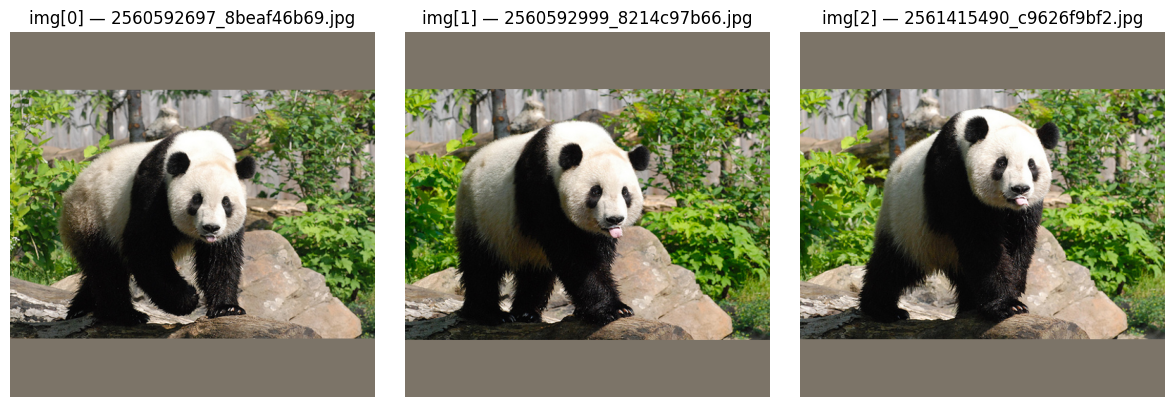

In [4]:
def build_canvas(path: Path, info):
    """Reconstrói o canvas keep_ar salvo pela E1 para alinhar os mapas."""
    image = Image.open(path).convert("RGB")
    if info is None:
        return image.resize((518, 518), Image.Resampling.BICUBIC)
    new_h, new_w, pad_top, pad_left, canvas_h, canvas_w = map(int, info)
    resized = image.resize((new_w, new_h), Image.Resampling.BICUBIC)
    mean = (0.485, 0.456, 0.406)
    pad_color = tuple(int(round(v * 255)) for v in mean)
    canvas = Image.new("RGB", (canvas_w, canvas_h), pad_color)
    canvas.paste(resized, (pad_left, pad_top))
    return canvas


canvases = [
    build_canvas(path, resize_infos[i] if resize_infos is not None else None)
    for i, path in enumerate(image_paths)
]

fig, axes = plt.subplots(1, N, figsize=(4 * N, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.imshow(canvases[i])
    ax.set_title(f"img[{i}] — {image_paths[i].name}")
    ax.axis("off")
plt.tight_layout()


## Passo 2 — máscara de conteúdo (padding)

Mesmo raciocínio das Etapas 1 e 2: se a Etapa 1 rodou com `--resize keep_ar`,
`resize_info` diz quais patches caem na faixa de padding. `step3_cosaliency.py`
**duplica** essa função (não importa de `step2_correspondence.py`) — o
comentário no próprio script explica que é proposital, seguindo o padrão de
scripts autocontidos usado em todo o pipeline (`step1`–`step5` não
compartilham um módulo utilitário comum).

Aqui o efeito de não mascarar é mais grave do que na Etapa 2: como o grafo
global tem um orçamento FIXO de `n_clusters`, e a entrada de padding é quase
constante entre todas as imagens, ela pode dominar clusters inteiros. O
docstring do script cita um caso real: coleções com muito padding e objeto
pequeno chegaram a gastar **4 de 5 clusters só com padding**, sobrando zero
clusters de conteúdo real para representar o objeto.


Total mascarado: 26.3% dos patches (todas as imagens)


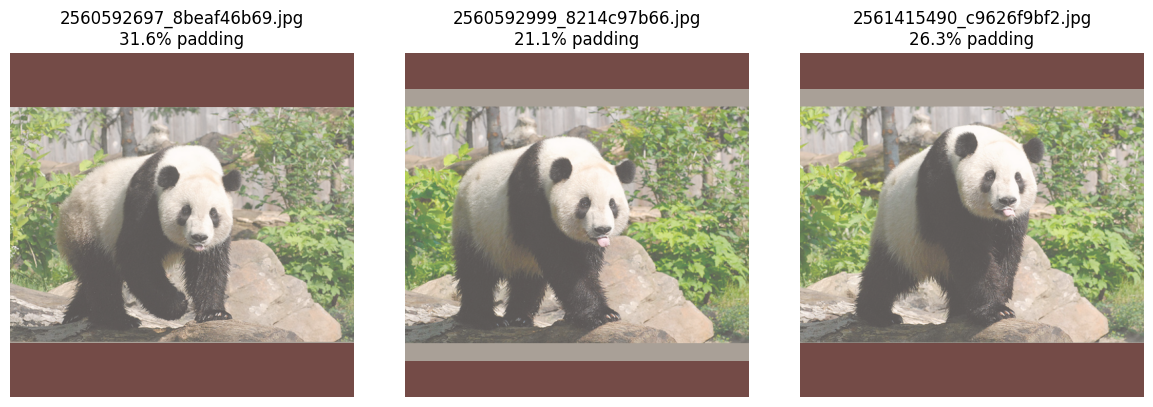

In [5]:
def compute_content_mask(resize_info, patch_grid):
    """Réplica de compute_content_mask() do step3_cosaliency.py (idêntica à
    versão em step2_correspondence.py, duplicada de propósito no script real)."""
    if resize_info is None:
        return None

    H_p_, W_p_ = patch_grid
    N_ = resize_info.shape[0]
    canvas_h, canvas_w = int(resize_info[0, 4]), int(resize_info[0, 5])
    patch_h = canvas_h / H_p_
    patch_w = canvas_w / W_p_

    row_starts = np.arange(H_p_) * patch_h
    col_starts = np.arange(W_p_) * patch_w
    row_ends = row_starts + patch_h
    col_ends = col_starts + patch_w

    masks = np.zeros((N_, H_p_, W_p_), dtype=bool)
    for i in range(N_):
        resized_h, resized_w, pad_top, pad_left, _, _ = [int(x) for x in resize_info[i]]
        content_row = (row_ends > pad_top) & (row_starts < pad_top + resized_h)
        content_col = (col_ends > pad_left) & (col_starts < pad_left + resized_w)
        masks[i] = content_row[:, None] & content_col[None, :]

    return masks.reshape(N_, -1)


content_mask = compute_content_mask(resize_infos, patch_grid) if USE_CONTENT_MASK else None

if content_mask is not None:
    fig, axes = plt.subplots(1, N, figsize=(4 * N, 4), squeeze=False)
    for i, path in enumerate(image_paths):
        m2d = content_mask[i].reshape(H_p, W_p)
        axes[0, i].imshow(canvases[i])
        axes[0, i].imshow(
            ~m2d, extent=(0, canvases[i].width, canvases[i].height, 0),
            cmap="Reds", alpha=0.35, vmin=0, vmax=1, interpolation="nearest",
        )
        axes[0, i].set_title(f"{path.name}\n{(1 - m2d.mean()):.1%} padding")
        axes[0, i].axis("off")
    plt.tight_layout()
    print(f"Total mascarado: {(1 - content_mask.mean()):.1%} dos patches (todas as imagens)")
else:
    print("Sem resize_info (Etapa 1 rodou em modo 'square') ou USE_CONTENT_MASK=False — nada a mascarar.")


## Passo 3 — escalonamento adaptativo de `n_clusters`

Mascarar o padding resolve a competição por clusters, mas cria um problema
novo: o orçamento `N_CLUSTERS` foi calibrado pensando no grafo COM padding.
Sem recalibrar, o mesmo número de clusters agora tem que representar só o
conteúdo real — nas classes testadas (`Ferrari`, `Track and Field`), isso
fragmentou o objeto em múltiplos clusters que cruzavam o threshold FG
individualmente (`Ferrari` foi de 1 para 3 clusters FG), prejudicando
`patch_iou`.

`compute_adaptive_n_clusters()` escala pela fração de conteúdo restante:

\[
n\_clusters_{efetivo} = \mathrm{round}\left(\frac{N\_CLUSTERS}{\text{fração de conteúdo}}\right)
\]

limitado por `MAX_N_CLUSTERS_ADAPTIVE`. Isso recupera ~75% da perda nas
classes testadas — é uma mitigação, não uma correção completa.


In [6]:
def compute_adaptive_n_clusters(base_n_clusters, content_mask, max_n_clusters=12):
    """Réplica de compute_adaptive_n_clusters() do step3_cosaliency.py."""
    if content_mask is None:
        return base_n_clusters
    content_fraction = float(content_mask.mean())
    if content_fraction >= 0.999:
        return base_n_clusters
    n = int(round(base_n_clusters / max(content_fraction, 0.1)))
    n = max(n, base_n_clusters)
    if max_n_clusters is not None:
        n = min(n, max_n_clusters)
    return n


n_clusters_effective = N_CLUSTERS
if content_mask is not None and USE_ADAPTIVE_CLUSTERS:
    n_clusters_effective = compute_adaptive_n_clusters(
        N_CLUSTERS, content_mask, max_n_clusters=MAX_N_CLUSTERS_ADAPTIVE
    )

print(f"n_clusters configurado: {N_CLUSTERS}")
print(f"n_clusters efetivo:     {n_clusters_effective}"
      + ("  (sem alteração)" if n_clusters_effective == N_CLUSTERS else "  (escalado pelo padding)"))


n_clusters configurado: 8
n_clusters efetivo:     11  (escalado pelo padding)


## Passo A — grafo global kNN esparso

Diferente do grafo par-a-par da Etapa 2 (denso, 2P×2P), aqui o grafo cobre a
coleção inteira (N·P nós) e precisa ser **esparso**: cada patch conecta só
aos seus `K_NEIGHBORS` vizinhos mais similares (de qualquer imagem, não só
da mesma). Se `content_mask` existir, patches de padding são **removidos**
do grafo inteiramente — não só zerados —, porque zerar afinidade ainda deixa
o nó lá, e dezenas de nós desconectados corromperiam a seleção do vetor de
Fiedler na etapa seguinte.


[Passo A] Construindo grafo global (3×361=1,083 nós)...
  Grafo: 798 nós de conteúdo (de 1,083 patches totais, 285 de padding excluídos)  |  7,723 arestas  (k=15)
  tempo: 0.06s


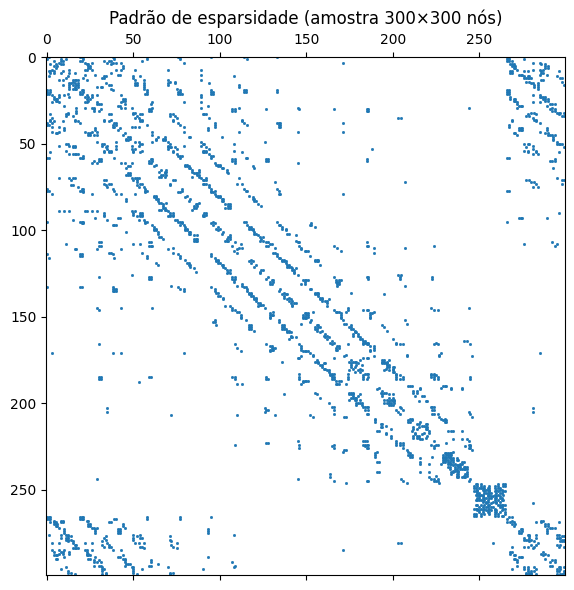

In [7]:
def build_global_graph(patch_features, k_neighbors, content_idx=None):
    """Réplica de build_global_graph() do step3_cosaliency.py."""
    N_, P_, D_ = patch_features.shape
    total = N_ * P_
    all_feats = l2_normalize(patch_features.reshape(total, D_), axis=1)

    feats = all_feats[content_idx] if content_idx is not None else all_feats
    M = feats.shape[0]

    rows, cols, data_v = [], [], []
    for i in range(M):
        sims = feats[i] @ feats.T
        sims[i] = -1.0
        top_k_idx = np.argpartition(sims, -k_neighbors)[-k_neighbors:]
        for j in top_k_idx:
            w = float(sims[j])
            if w > 0:
                rows.extend([i, int(j)])
                cols.extend([int(j), i])
                data_v.extend([w, w])

    W = csr_matrix((data_v, (rows, cols)), shape=(M, M))
    n_edges = W.nnz // 2
    if content_idx is not None:
        print(f"  Grafo: {M:,} nós de conteúdo (de {total:,} patches totais, "
              f"{total - M:,} de padding excluídos)  |  {n_edges:,} arestas  "
              f"(k={k_neighbors})")
    else:
        print(f"  Grafo: {M:,} nós  |  {n_edges:,} arestas  (k={k_neighbors})")
    return W


content_idx = None
if content_mask is not None:
    content_idx = np.flatnonzero(content_mask.reshape(-1))

print(f"[Passo A] Construindo grafo global ({N}×{P}={N*P:,} nós)...")
t0 = time.time()
W_global = build_global_graph(patch_features, K_NEIGHBORS, content_idx=content_idx)
print(f"  tempo: {time.time()-t0:.2f}s")

fig, ax = plt.subplots(figsize=(6, 6))
sample = W_global[:min(300, W_global.shape[0]), :min(300, W_global.shape[0])]
ax.spy(sample, markersize=1)
ax.set_title(f"Padrão de esparsidade (amostra {sample.shape[0]}×{sample.shape[0]} nós)")
plt.tight_layout()


## Passo B — embedding espectral

Mesma ideia da Etapa 2 (Laplaciano normalizado, `L_sym = I - D^{-1/2} W D^{-1/2}`),
mas agora resolvido de forma **esparsa** (`scipy.sparse.linalg.eigsh`) em vez
de denso (`np.linalg.eigh`) — o grafo tem milhares de nós, uma decomposição
densa seria proibitiva. `eigsh` busca só os `N_SPECTRAL+1` menores
autovalores (`which="SM"`), não a decomposição completa.

O autovetor 0 é trivial (constante) e é descartado — os autovetores
`1..N_SPECTRAL` formam o embedding onde a distância euclidiana aproxima a
distância geodésica no grafo (patches "alcançáveis" um do outro por um
caminho de alta afinidade ficam próximos no embedding, mesmo que sua
similaridade coseno direta seja baixa).


[Passo B] Spectral embedding (8 componentes)...
  Autovalores (1..8): [0.0077 0.0103 0.0241 0.0259 0.0329 0.0395 0.0591 0.0643]
  tempo: 0.03s  |  embedding: (798, 8)


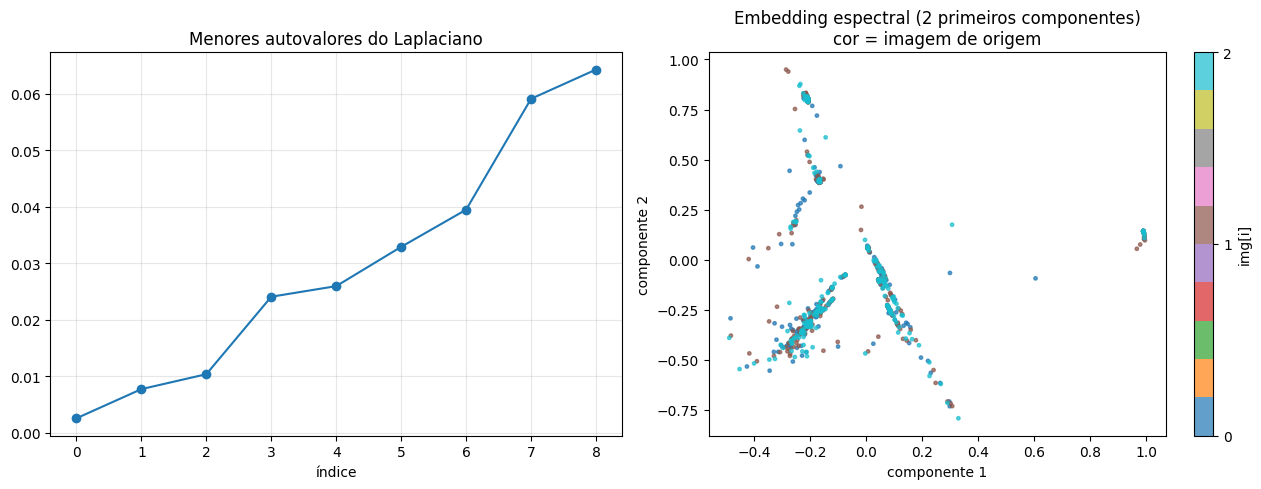

In [8]:
def spectral_embedding(W, n_components):
    """Réplica de spectral_embedding() do step3_cosaliency.py."""
    total = W.shape[0]
    d = np.array(W.sum(axis=1)).flatten()
    D_inv = sp_diags(1.0 / np.sqrt(np.maximum(d, 1e-8)))
    L_sym = sp_diags(np.ones(total)) - D_inv @ W @ D_inv

    eigenvalues, eigenvectors = eigsh(
        L_sym, k=n_components + 1, which="SM", tol=1e-4, maxiter=1000,
    )
    order = np.argsort(eigenvalues)
    eigenvectors = eigenvectors[:, order]
    embed = l2_normalize(eigenvectors[:, 1:n_components + 1], axis=1)

    print(f"  Autovalores (1..{n_components}): {eigenvalues[order][1:n_components+1].round(4)}")
    return embed.astype(np.float32), eigenvalues[order]


print(f"[Passo B] Spectral embedding ({N_SPECTRAL} componentes)...")
t0 = time.time()
embed, eigvals = spectral_embedding(W_global, N_SPECTRAL)
print(f"  tempo: {time.time()-t0:.2f}s  |  embedding: {embed.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(eigvals[:min(len(eigvals), 15)], "o-")
axes[0].set_title("Menores autovalores do Laplaciano")
axes[0].set_xlabel("índice"); axes[0].grid(alpha=.3)

# Dispersão nos 2 primeiros componentes espectrais, colorida por imagem de origem
if content_idx is not None:
    owner_img = (content_idx // P)
else:
    owner_img = np.repeat(np.arange(N), P)
sc = axes[1].scatter(embed[:, 0], embed[:, 1], c=owner_img, cmap="tab10", s=6, alpha=.7)
axes[1].set_title("Embedding espectral (2 primeiros componentes)\ncor = imagem de origem")
axes[1].set_xlabel("componente 1"); axes[1].set_ylabel("componente 2")
plt.colorbar(sc, ax=axes[1], label="img[i]", ticks=range(N))
plt.tight_layout()


## Passo C — k-means espectral

Agrupa os patches no espaço espectral (não no espaço DINOv2 original) em
`n_clusters_effective` clusters. Como a geometria do grafo já capturou
estrutura cross-image, clusters aqui tendem a agrupar regiões semanticamente
parecidas *entre* imagens diferentes, não só dentro de uma imagem.


[Passo C] K-means espectral (11 clusters)...
  Clusters (tamanho): C0=80  C1=108  C2=98  C3=75  C4=82  C5=88  C6=74  C7=71  C8=58  C9=28  C10=36


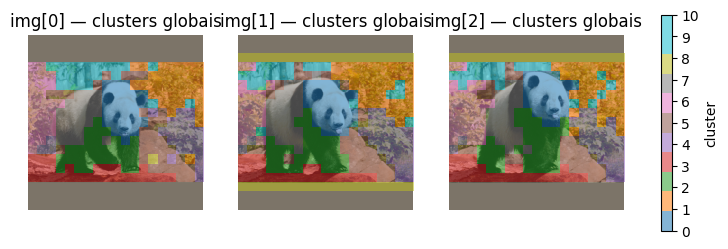

In [9]:
def spectral_kmeans(embed, n_clusters, random_state=42):
    """Réplica de spectral_kmeans() do step3_cosaliency.py."""
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=random_state)
    labels = km.fit_predict(embed)
    counts = np.bincount(labels, minlength=n_clusters)
    print(f"  Clusters (tamanho): " + "  ".join(f"C{i}={c}" for i, c in enumerate(counts)))
    return labels.astype(np.int32)


print(f"[Passo C] K-means espectral ({n_clusters_effective} clusters)...")
labels_content = spectral_kmeans(embed, n_clusters_effective)

# Espalha de volta para o espaço completo (N·P). Patches de padding (fora de
# content_idx) recebem rótulo arbitrário 0 só para manter os arrays
# indexáveis — nunca competem por FG (forçados a 0 no Passo E).
total = N * P
if content_idx is not None:
    labels_full = np.zeros(total, dtype=np.int64)
    labels_full[content_idx] = labels_content
    is_padding_flat = np.ones(total, dtype=bool)
    is_padding_flat[content_idx] = False
else:
    labels_full = labels_content
    is_padding_flat = np.zeros(total, dtype=bool)

labels_img = labels_full.reshape(N, H_p, W_p)

cmap_clusters = plt.get_cmap("tab10", n_clusters_effective)
fig, axes = plt.subplots(1, N, figsize=(3.2 * N, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.imshow(canvases[i])
    show = np.ma.masked_where(is_padding_flat.reshape(N, H_p, W_p)[i], labels_img[i])
    im = ax.imshow(show, cmap=cmap_clusters, vmin=0, vmax=n_clusters_effective - 1,
                   alpha=.55, extent=(0, canvases[i].width, canvases[i].height, 0),
                   interpolation="nearest")
    ax.set_title(f"img[{i}] — clusters globais")
    ax.axis("off")
fig.colorbar(im, ax=axes[0].tolist(), shrink=.7, ticks=range(n_clusters_effective), label="cluster")
plt.show()


## Passo D — saliência espacial por cluster

O score bruto da Etapa 2 (`fg_scores`) tem um ponto cego: fundo estruturado
(bandas de céu, chão, grama) aparece de forma consistente entre as imagens,
então recebe score de correspondência alto — mesmo sem ser o objeto de
interesse. Dois critérios geométricos complementares corrigem isso:

- **centralidade**: distância média dos patches do cluster ao centro da
  imagem (invertida — cluster central pontua alto). Viés do fotógrafo: o
  objeto tende a estar no centro.
- **compacidade**: dispersão espacial dos patches (invertida — cluster
  compacto pontua alto). Objetos formam blobs; fundo estruturado se espalha
  em faixas.

O score espacial final é a média geométrica dos dois — penaliza um cluster
que só é bom em um dos dois critérios:

\[
\text{score\\_spatial} = \sqrt{\text{centralidade} \times \text{compacidade}}
\]


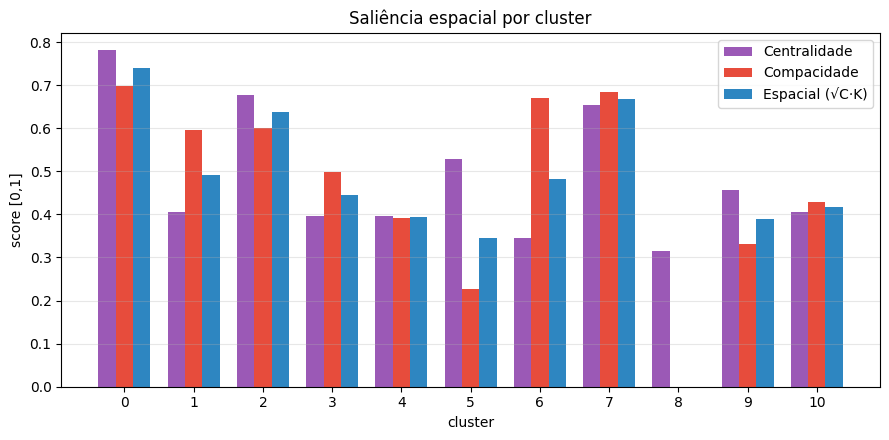

In [10]:
def compute_spatial_saliency(labels_flat, patch_grid, n_images, n_clusters, content_idx=None):
    """Réplica de compute_spatial_saliency() do step3_cosaliency.py."""
    H_p_, W_p_ = patch_grid
    row_coords = np.repeat(np.arange(H_p_), W_p_) / (H_p_ - 1 + 1e-8)
    col_coords = np.tile(np.arange(W_p_), H_p_) / (W_p_ - 1 + 1e-8)
    rows_all = np.tile(row_coords, n_images)
    cols_all = np.tile(col_coords, n_images)
    if content_idx is not None:
        rows_all = rows_all[content_idx]
        cols_all = cols_all[content_idx]

    max_dist = np.sqrt(0.5 ** 2 + 0.5 ** 2)
    dist_center = np.sqrt((rows_all - 0.5) ** 2 + (cols_all - 0.5) ** 2) / max_dist

    score_centrality = np.zeros(n_clusters, dtype=np.float32)
    score_compactness = np.zeros(n_clusters, dtype=np.float32)
    for c in range(n_clusters):
        mask = labels_flat == c
        if not mask.any():
            continue
        score_centrality[c] = 1.0 - float(dist_center[mask].mean())
        std_rows = float(rows_all[mask].std())
        std_cols = float(cols_all[mask].std())
        score_compactness[c] = 1.0 - min(((std_rows + std_cols) / 2.0) / 0.289, 1.0)

    score_spatial = np.sqrt(score_centrality * score_compactness)
    return score_spatial, score_centrality, score_compactness


score_spatial, score_centrality, score_compactness = compute_spatial_saliency(
    labels_content, patch_grid, N, n_clusters_effective, content_idx=content_idx
)

cluster_ids = np.arange(n_clusters_effective)
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_w = 0.25
ax.bar(cluster_ids - bar_w, score_centrality, width=bar_w, label="Centralidade", color="#9B59B6")
ax.bar(cluster_ids,          score_compactness, width=bar_w, label="Compacidade", color="#E74C3C")
ax.bar(cluster_ids + bar_w,  score_spatial,     width=bar_w, label="Espacial (√C·K)", color="#2E86C1")
ax.set_xticks(cluster_ids); ax.set_xlabel("cluster"); ax.set_ylabel("score [0,1]")
ax.set_title("Saliência espacial por cluster"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout()


### Extra — prior de borda (`fg_decision_mode='e2_border_topk'`, experimental)

O prior espacial do Passo D ataca clusters de fundo estruturado que são
*periféricos ou dispersos*. Ele não ajuda quando o **próprio** `score_e2` já
erra — cenas onde o fundo é mais consistente entre as imagens do que o
objeto (ex.: times de futebol: o gramado nunca muda, os jogadores sim).
`compute_border_prior()` ataca esse caso com geometria pura por cluster
(fração de patches tocando a borda da grade, sem nenhuma comparação
estatística entre imagens):

Validado via ablação (`ablation/analyze_geometric_priors.py`) nas 14 classes
do subset icoseg16: melhora média e pior-caso, resolvendo bem os casos tipo
"gramado" (`Liverpool`, `Red Sox Players`), mas com custo real em 2 classes
(`Kite`, `Statue`). **Por isso não é o default** — precisa ser ligado
explicitamente (`FG_DECISION_MODE = "e2_border_topk"`). Quando ligado, a
decisão também muda de "limiar" para "top-K por ranking" (`TOPK_FRACTION`),
porque um limiar fixo não é robusto quando a escala do score muda com a
mistura E2+borda.


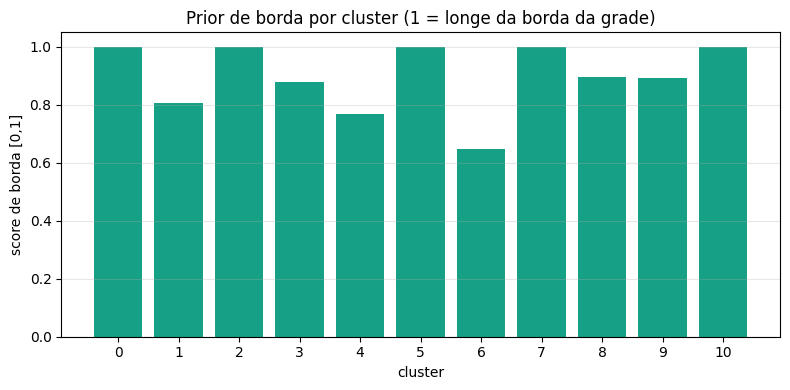

In [11]:
def compute_border_prior(labels_flat, patch_grid, n_images, n_clusters, content_idx=None):
    """Réplica de compute_border_prior() do step3_cosaliency.py."""
    H_p_, W_p_ = patch_grid
    row_idx = np.repeat(np.arange(H_p_), W_p_)
    col_idx = np.tile(np.arange(W_p_), H_p_)
    rows_all = np.tile(row_idx, n_images)
    cols_all = np.tile(col_idx, n_images)
    if content_idx is not None:
        rows_all = rows_all[content_idx]
        cols_all = cols_all[content_idx]

    on_border = (rows_all == 0) | (rows_all == H_p_ - 1) | (cols_all == 0) | (cols_all == W_p_ - 1)

    score_border = np.zeros(n_clusters, dtype=np.float32)
    for c in range(n_clusters):
        mask = labels_flat == c
        if not mask.any():
            continue
        score_border[c] = 1.0 - float(on_border[mask].mean())
    return score_border


score_border = None
if FG_DECISION_MODE == "e2_border_topk":
    score_border = compute_border_prior(labels_content, patch_grid, N, n_clusters_effective,
                                        content_idx=content_idx)

# Demonstração lado a lado, independente de FG_DECISION_MODE, só para comparar:
score_border_demo = compute_border_prior(labels_content, patch_grid, N,
                                          n_clusters_effective, content_idx=content_idx)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cluster_ids, score_border_demo, color="#16A085")
ax.set_xticks(cluster_ids); ax.set_xlabel("cluster"); ax.set_ylabel("score de borda [0,1]")
ax.set_title("Prior de borda por cluster (1 = longe da borda da grade)")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()


## Passo E — mapeamento cluster → foreground/background

Cada cluster recebe um score final e uma decisão binária FG/BG, por um dos
dois mecanismos:

- **`"saliency"` (default/produção)**: combinação convexa
  `score_final = (1-α)·score_e2 + α·score_spatial`, decisão por limiar
  (`score_final > FG_THRESHOLD`).
- **`"e2_border_topk"` (experimental)**: combinação com o prior de borda em
  vez do espacial, decisão por top-K no ranking (não por limiar).

O resultado é espalhado de volta para o espaço completo (`N·P`): patches de
padding recebem rótulo de cluster arbitrário (0) só para manter os arrays
indexáveis, mas a máscara final os força explicitamente para background,
**independente do que o "cluster 0" representa** para o conteúdo real.


4/11 clusters classificados como FG (modo=saliency)


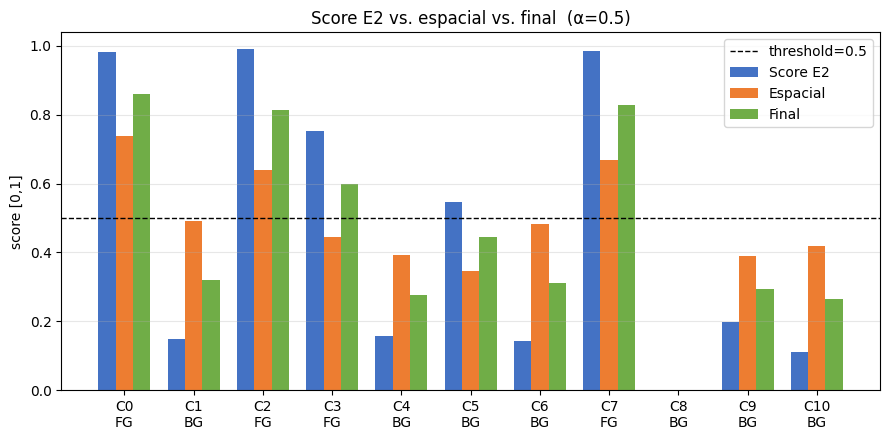

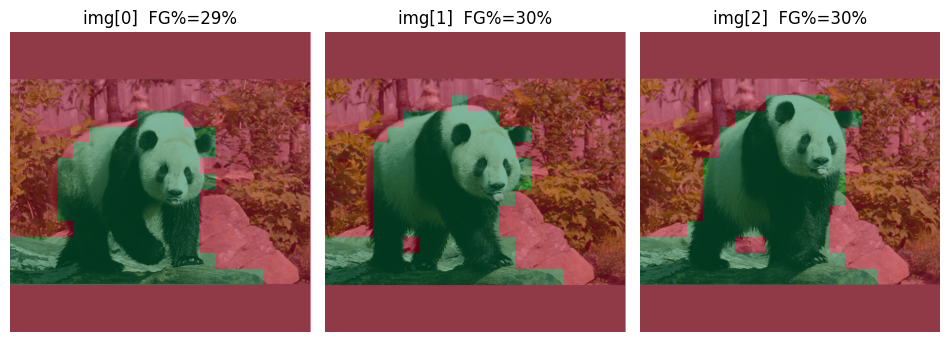

In [12]:
def map_clusters_to_fg(labels_flat, fg_scores_e2, score_spatial, n_clusters,
                       fg_threshold=0.5, saliency_alpha=0.5,
                       fg_decision_mode="saliency", score_border=None,
                       e2_border_weight=0.3, topk_fraction=0.30):
    """Réplica de map_clusters_to_fg() do step3_cosaliency.py."""
    fg_flat = fg_scores_e2.flatten()
    score_e2 = np.array([
        fg_flat[labels_flat == c].mean() if (labels_flat == c).any() else 0.5
        for c in range(n_clusters)
    ], dtype=np.float32)

    if fg_decision_mode == "e2_border_topk":
        score_final = (1.0 - e2_border_weight) * score_e2 + e2_border_weight * score_border
        k = max(1, int(np.ceil(topk_fraction * n_clusters)))
        order = np.argsort(-score_final)
        cluster_is_fg = np.zeros(n_clusters, dtype=bool)
        cluster_is_fg[order[:k]] = True
    elif fg_decision_mode == "saliency":
        score_final = (1.0 - saliency_alpha) * score_e2 + saliency_alpha * score_spatial
        cluster_is_fg = score_final > fg_threshold
    else:
        raise ValueError(fg_decision_mode)

    fg_score_map = score_final[labels_flat]
    return score_e2, score_final, cluster_is_fg, fg_score_map


if content_idx is not None:
    fg_scores_e2_for_map = fg_scores.reshape(-1)[content_idx]
else:
    fg_scores_e2_for_map = fg_scores

score_e2, score_final, cluster_is_fg, fg_score_map_content = map_clusters_to_fg(
    labels_content, fg_scores_e2_for_map, score_spatial, n_clusters_effective,
    FG_THRESHOLD, SALIENCY_ALPHA,
    fg_decision_mode=FG_DECISION_MODE, score_border=score_border,
    e2_border_weight=E2_BORDER_WEIGHT, topk_fraction=TOPK_FRACTION,
)

print(f"{cluster_is_fg.sum()}/{n_clusters_effective} clusters classificados como FG "
      f"(modo={FG_DECISION_MODE})")

# Espalha de volta para o espaço completo
if content_idx is not None:
    fg_score_global_flat = np.zeros(total, dtype=np.float32)
    fg_score_global_flat[content_idx] = fg_score_map_content
else:
    fg_score_global_flat = fg_score_map_content

fg_mask_coarse_flat = cluster_is_fg[labels_full].astype(np.float32)
fg_mask_coarse_flat[is_padding_flat] = 0.0
fg_mask_coarse = fg_mask_coarse_flat.reshape(N, H_p, W_p)
fg_score_global = fg_score_global_flat.reshape(N, H_p, W_p)

# Gráfico: score E2 vs espacial vs final, por cluster
bar_w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(cluster_ids - bar_w, score_e2,    width=bar_w, label="Score E2", color="#4472C4")
ax.bar(cluster_ids,          score_spatial, width=bar_w, label="Espacial", color="#ED7D31")
ax.bar(cluster_ids + bar_w,  score_final,  width=bar_w, label="Final", color="#70AD47")
ax.axhline(FG_THRESHOLD, color="black", ls="--", lw=1, label=f"threshold={FG_THRESHOLD}")
ax.set_xticks(cluster_ids)
ax.set_xticklabels([f"C{c}\n{('FG' if cluster_is_fg[c] else 'BG')}" for c in cluster_ids])
ax.set_ylabel("score [0,1]"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title(f"Score E2 vs. espacial vs. final  (α={SALIENCY_ALPHA})")
plt.tight_layout()

# Mapa coarse por imagem
fig, axes = plt.subplots(1, N, figsize=(3.2 * N, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.imshow(canvases[i])
    ax.imshow(fg_mask_coarse[i], cmap="RdYlGn", vmin=0, vmax=1, alpha=.5,
             extent=(0, canvases[i].width, canvases[i].height, 0), interpolation="nearest")
    ax.set_title(f"img[{i}]  FG%={fg_mask_coarse[i].mean()*100:.0f}%")
    ax.axis("off")
plt.tight_layout()


## Passo F — refinamento NCut intra-imagem (opcional, desativado por padrão)

O grafo global (Passo A) mistura patches de todas as imagens — ótimo para
achar consenso cross-image, mas a resolução do corte fica limitada pelo
tamanho dos clusters. `ncut_intra_refine()` roda um NCut local, imagem por
imagem (só `P` nós, decomposição densa rápida), usando a máscara coarse como
prior:

\[
w(p,q) = \cos\_sim(p,q)\cdot\bigl(1-|fg\_prior[p]-fg\_prior[q]|\bigr)
\]

isto é, dois patches só ficam fortemente conectados se forem parecidos
*e* o prior (`fg_scores` da E2) concordar que pertencem ao mesmo lado. A
orientação FG/BG usa o lado do Fiedler com maior `fg_prior` médio — mesmo
padrão de orientação por saliência das Etapas 2/3.

O docstring do script é direto: isso é **experimental e desativado por
padrão** — pode substituir uma máscara global de boa qualidade por uma
partição local pior, porque não é estritamente condicionado pela máscara
coarse. `run_pipeline.sh` também não liga `--refine`. Mostramos os dois
resultados lado a lado para você decidir caso a caso.


REFINE = False  →  máscara final = coarse (clusters globais)


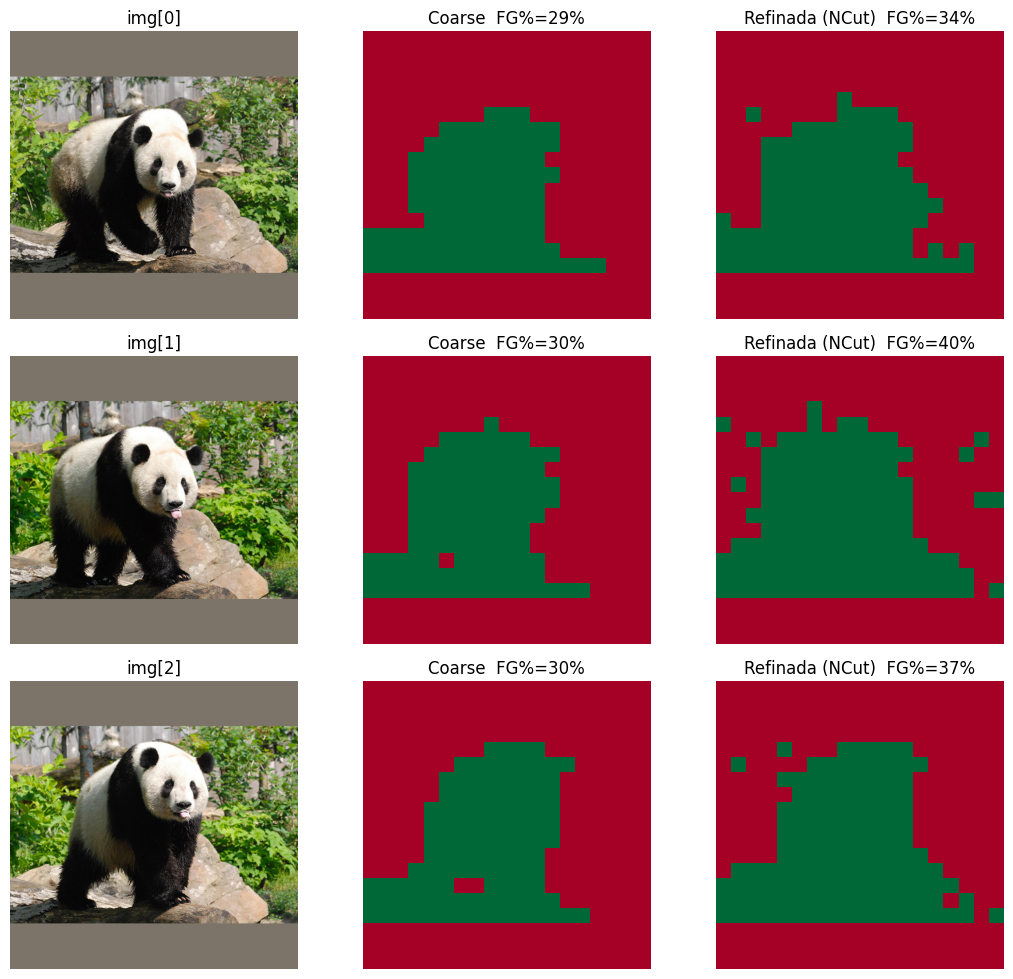

In [13]:
def ncut_intra_refine(feat_i, fg_prior, temperature=0.07, content_mask_i=None):
    """Réplica de ncut_intra_refine() do step3_cosaliency.py."""
    P_ = feat_i.shape[0]
    if content_mask_i is not None and content_mask_i.sum() < P_:
        idx = np.flatnonzero(content_mask_i)
        if idx.size == 0:
            idx = np.arange(P_)
    else:
        idx = np.arange(P_)

    feat_c = feat_i[idx]
    prior_c = fg_prior[idx]

    fi = l2_normalize(feat_c, axis=1)
    W = np.maximum(fi @ fi.T, 0.0)
    np.fill_diagonal(W, 0.0)

    prior_agree = 1.0 - np.abs(prior_c[:, None] - prior_c[None, :])
    W = W * prior_agree

    d = W.sum(axis=1)
    d_inv = 1.0 / np.sqrt(np.maximum(d, 1e-8))
    L_sym = np.eye(len(feat_c), dtype=np.float32) - (d_inv[:, None] * W * d_inv[None, :])

    _, vecs = np.linalg.eigh(L_sym)
    fiedler = vecs[:, 1]

    side = fiedler > np.median(fiedler)
    if prior_c[side].mean() < prior_c[~side].mean():
        side = ~side

    fg_full = np.zeros(P_, dtype=np.float32)
    fg_full[idx] = side.astype(np.float32)
    return fg_full


# Roda sempre os dois (para comparação visual), mas só usa REFINE para decidir
# qual vira a máscara final (fg_mask_refined), como no script real.
fg_mask_refine_demo = np.zeros((N, P), dtype=np.float32)
for i in range(N):
    content_mask_i = content_mask[i] if content_mask is not None else None
    fg_mask_refine_demo[i] = ncut_intra_refine(
        patch_features[i], fg_scores[i], content_mask_i=content_mask_i
    )

fg_mask_refined = fg_mask_refine_demo.reshape(N, H_p, W_p) if REFINE else fg_mask_coarse
print(f"REFINE = {REFINE}  →  máscara final = "
      f"{'refinada (NCut intra-imagem)' if REFINE else 'coarse (clusters globais)'}")

fig, axes = plt.subplots(N, 3, figsize=(11, 3.3 * N), squeeze=False)
for i in range(N):
    axes[i, 0].imshow(canvases[i]); axes[i, 0].set_title(f"img[{i}]")
    axes[i, 1].imshow(fg_mask_coarse[i], cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest")
    axes[i, 1].set_title(f"Coarse  FG%={fg_mask_coarse[i].mean()*100:.0f}%")
    axes[i, 2].imshow(fg_mask_refine_demo[i].reshape(H_p, W_p), cmap="RdYlGn", vmin=0, vmax=1,
                      interpolation="nearest")
    axes[i, 2].set_title(f"Refinada (NCut)  FG%={fg_mask_refine_demo[i].mean()*100:.0f}%")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout()


## Passo G — upsample para o tamanho original

A máscara está na resolução de patches (`H_p × W_p`). Se a Etapa 1 rodou com
`keep_ar`, o canvas cobre imagem + padding — reamostrar direto para o
tamanho original esticaria/deslocaria a máscara. `upsample_masks()` primeiro
**recorta** a região de padding do canvas (usando `resize_info`) e só depois
redimensiona para o tamanho original.


Máscaras pixel: (3, 344, 500)  FG% médio = 43.4%


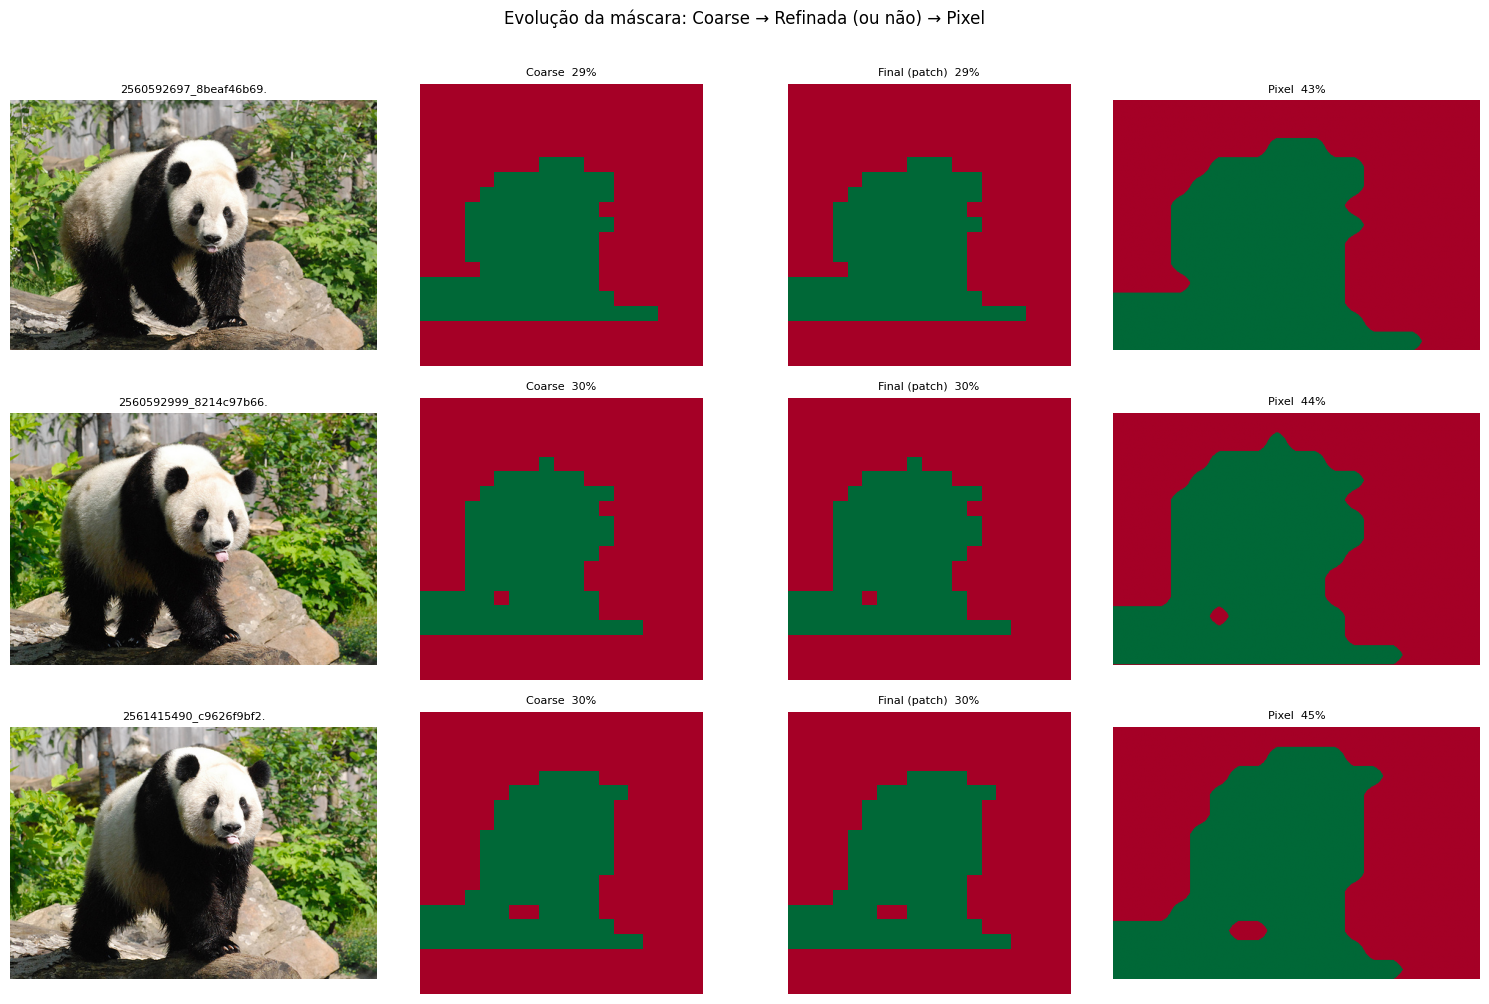

In [14]:
def upsample_masks(fg_masks_patch, image_sizes, resize_info=None, threshold=0.5):
    """Réplica de upsample_masks() do step3_cosaliency.py."""
    N_ = fg_masks_patch.shape[0]
    H_max = int(image_sizes[:, 0].max())
    W_max = int(image_sizes[:, 1].max())
    output = np.zeros((N_, H_max, W_max), dtype=np.float32)

    for i in range(N_):
        H_orig, W_orig = int(image_sizes[i, 0]), int(image_sizes[i, 1])
        mask_img = Image.fromarray((fg_masks_patch[i] * 255).astype(np.uint8))

        if resize_info is not None:
            resized_h, resized_w, pad_top, pad_left, canvas_h, canvas_w = \
                [int(x) for x in resize_info[i]]
            canvas_mask = mask_img.resize((canvas_w, canvas_h), Image.BILINEAR)
            canvas_arr = np.array(canvas_mask)
            crop = canvas_arr[pad_top:pad_top + resized_h, pad_left:pad_left + resized_w]
            up = np.array(Image.fromarray(crop).resize((W_orig, H_orig), Image.BILINEAR)) / 255.0
        else:
            up = np.array(mask_img.resize((W_orig, H_orig), Image.BILINEAR)) / 255.0

        hard = (up > threshold).astype(np.float32)
        output[i, :H_orig, :W_orig] = hard

    return output


fg_mask_pixel = upsample_masks(fg_mask_refined, image_sizes, resize_info=resize_infos)
print(f"Máscaras pixel: {fg_mask_pixel.shape}  FG% médio = {fg_mask_pixel.mean()*100:.1f}%")

N_vis = N
fig, axes = plt.subplots(N_vis, 4, figsize=(15, 3.3 * N_vis), squeeze=False)
fig.suptitle("Evolução da máscara: Coarse → Refinada (ou não) → Pixel", y=1.01)
for i in range(N_vis):
    H_i, W_i = int(image_sizes[i, 0]), int(image_sizes[i, 1])
    img = Image.open(image_paths[i]).convert("RGB")
    axes[i, 0].imshow(img); axes[i, 0].set_title(Path(image_paths[i]).name[:22], fontsize=8)
    axes[i, 1].imshow(fg_mask_coarse[i], cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest")
    axes[i, 1].set_title(f"Coarse  {fg_mask_coarse[i].mean()*100:.0f}%", fontsize=8)
    axes[i, 2].imshow(fg_mask_refined[i], cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest")
    axes[i, 2].set_title(f"Final (patch)  {fg_mask_refined[i].mean()*100:.0f}%", fontsize=8)
    axes[i, 3].imshow(fg_mask_pixel[i, :H_i, :W_i], cmap="RdYlGn", vmin=0, vmax=1)
    axes[i, 3].set_title(f"Pixel  {fg_mask_pixel[i,:H_i,:W_i].mean()*100:.0f}%", fontsize=8)
    for ax in axes[i]: ax.axis("off")
plt.tight_layout()


## Passo H — seeds para a Etapa 4 (SAM prompting)

Última etapa: extrair, por imagem, uma bounding box, pontos de FG e pontos
de BG a partir da máscara pixel — a entrada que a Etapa 4 (SAM) espera. Os
pontos de BG preferem os cantos/bordas da imagem (mais provável de ser fundo
real), caindo para amostragem geral só se não houver cantos livres o
suficiente.


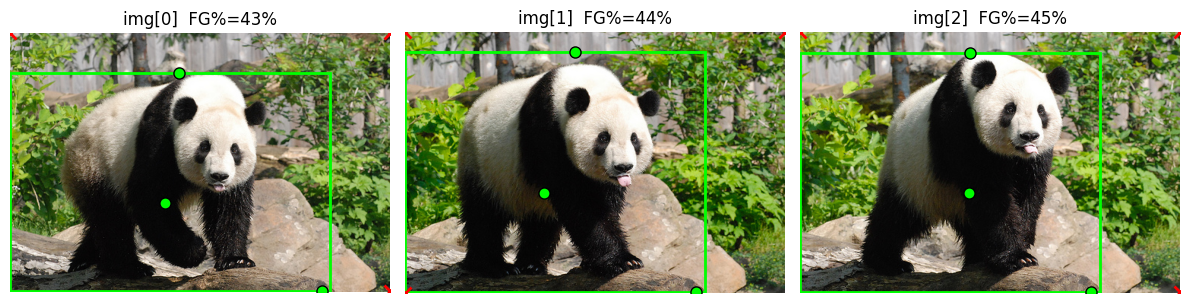

In [15]:
def extract_seeds(fg_masks_pixel, image_sizes, n_fg_points=3, n_bg_points=3):
    """Réplica de extract_seeds() do step3_cosaliency.py."""
    N_ = fg_masks_pixel.shape[0]
    seeds = []
    for i in range(N_):
        H_i, W_i = int(image_sizes[i, 0]), int(image_sizes[i, 1])
        mask = fg_masks_pixel[i, :H_i, :W_i]

        fg_pts = np.argwhere(mask > 0.5)
        bg_pts = np.argwhere(mask < 0.5)

        if len(fg_pts) > 0:
            r0, c0 = fg_pts.min(axis=0); r1, c1 = fg_pts.max(axis=0)
            bbox = [int(c0), int(r0), int(c1), int(r1)]
        else:
            bbox = [0, 0, W_i, H_i]

        if len(fg_pts) >= n_fg_points:
            idx = np.linspace(0, len(fg_pts) - 1, n_fg_points, dtype=int)
            fg_sampled = fg_pts[idx].tolist()
        else:
            fg_sampled = fg_pts.tolist()

        corners = np.array([
            [0, 0], [0, W_i - 1], [H_i - 1, 0], [H_i - 1, W_i - 1],
            [H_i // 2, 0], [H_i // 2, W_i - 1], [0, W_i // 2], [H_i - 1, W_i // 2],
        ])
        corner_bg = [pt for pt in corners
                     if 0 <= pt[0] < H_i and 0 <= pt[1] < W_i and mask[pt[0], pt[1]] < 0.5]
        if len(corner_bg) >= n_bg_points:
            bg_sampled = corner_bg[:n_bg_points]
        elif len(bg_pts) >= n_bg_points:
            idx = np.linspace(0, len(bg_pts) - 1, n_bg_points, dtype=int)
            bg_sampled = bg_pts[idx].tolist()
        else:
            bg_sampled = bg_pts.tolist()

        seeds.append({
            "bbox": bbox,
            "fg_points": [pt if isinstance(pt, list) else pt.tolist() for pt in fg_sampled],
            "bg_points": [pt if isinstance(pt, list) else pt.tolist() for pt in bg_sampled],
            "fg_ratio": float(mask.mean()),
        })
    return seeds


seeds = extract_seeds(fg_mask_pixel, image_sizes)

fig, axes = plt.subplots(1, N, figsize=(4 * N, 4.5), squeeze=False)
for i, ax in enumerate(axes[0]):
    H_i, W_i = int(image_sizes[i, 0]), int(image_sizes[i, 1])
    img = Image.open(image_paths[i]).convert("RGB")
    ax.imshow(img)
    x0, y0, x1, y1 = seeds[i]["bbox"]
    ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                    fill=False, edgecolor="lime", linewidth=2))
    for r, c in seeds[i]["fg_points"]:
        ax.plot(c, r, "o", color="lime", markersize=8, markeredgecolor="black")
    for r, c in seeds[i]["bg_points"]:
        ax.plot(c, r, "x", color="red", markersize=9, markeredgewidth=2)
    ax.set_title(f"img[{i}]  FG%={seeds[i]['fg_ratio']*100:.0f}%")
    ax.axis("off")
plt.tight_layout()


## Passo 4 (salvar) — o artefato didático

Com `PATCH_STRIDE=1` na Etapa 2 (e portanto aqui também), as dimensões
correspondem à resolução integral do pipeline. Com stride maior, o arquivo é
só didático e não deve ser entregue à Etapa 4 real.


In [16]:
output_path = Path("cosaliency_notebook.npz")
seeds_arr = np.empty(len(seeds), dtype=object)
for i, s in enumerate(seeds):
    seeds_arr[i] = s

np.savez_compressed(
    output_path,
    fg_mask_patch=fg_mask_refined,
    fg_mask_pixel=fg_mask_pixel,
    fg_score_global=fg_score_global,
    fg_mask_coarse=fg_mask_coarse,
    cluster_labels=labels_img,
    cluster_scores=score_final,
    cluster_scores_e2=score_e2,
    cluster_scores_sp=score_spatial,
    cluster_scores_centrality=score_centrality,
    cluster_scores_compactness=score_compactness,
    cluster_is_fg=cluster_is_fg,
    n_clusters_used=np.array(n_clusters_effective),
    saliency_alpha=np.array(SALIENCY_ALPHA),
    fg_decision_mode=np.array(FG_DECISION_MODE),
    e2_border_weight=np.array(E2_BORDER_WEIGHT),
    topk_fraction=np.array(TOPK_FRACTION),
    refine=np.array(REFINE),
    seeds=seeds_arr,
    image_paths=np.asarray([str(p) for p in image_paths]),
    image_sizes=image_sizes,
    patch_grid=np.asarray((H_p, W_p)),
)

saved = np.load(output_path, allow_pickle=True)
print("Salvo em:", output_path.resolve())
for key in saved.files:
    value = saved[key]
    shape = getattr(value, "shape", None)
    print(f"  {key:28s} shape={str(shape):16s} dtype={value.dtype}")


Salvo em: /mnt/e/github/cosegmentation/study/cosaliency_notebook.npz
  fg_mask_patch                shape=(3, 19, 19)      dtype=float32
  fg_mask_pixel                shape=(3, 344, 500)    dtype=float32
  fg_score_global              shape=(3, 19, 19)      dtype=float32
  fg_mask_coarse               shape=(3, 19, 19)      dtype=float32
  cluster_labels               shape=(3, 19, 19)      dtype=int64
  cluster_scores               shape=(11,)            dtype=float32
  cluster_scores_e2            shape=(11,)            dtype=float32
  cluster_scores_sp            shape=(11,)            dtype=float32
  cluster_scores_centrality    shape=(11,)            dtype=float32
  cluster_scores_compactness   shape=(11,)            dtype=float32
  cluster_is_fg                shape=(11,)            dtype=bool
  n_clusters_used              shape=()               dtype=int64
  saliency_alpha               shape=()               dtype=float64
  fg_decision_mode             shape=()               

## Mapa mental final

```text
features.npz (E1)          correspondence.npz (E2)
     └── patch_features          └── fg_scores, cls_saliency
                    \\                /
                     \\              /
              [opcional] excluir padding (content_mask)
                          |
              [opcional] escalar n_clusters (compute_adaptive_n_clusters)
                          |
                 grafo global kNN esparso (Passo A)
                          |
                spectral embedding (Passo B — eigsh)
                          |
                k-means espectral (Passo C)
                     /          \\
        saliência espacial   prior de borda (extra, e2_border_topk)
     (centralidade+compac.)          |
                     \\              /
              mapeamento cluster → FG/BG (Passo E)
                          |
        [opcional, off por padrão] refino NCut intra-imagem (Passo F)
                          |
                upsample para pixel (Passo G)
                          |
                seeds para a Etapa 4 (Passo H)
```

A Etapa 3 é a primeira a produzir uma **máscara binária** (não mais um score
contínuo por votação) — e a primeira a olhar a coleção inteira de uma vez em
vez de pares. Ela também é, das três, a que mais depende de escolhas
geométricas explícitas (centralidade, compacidade, borda) em vez de só
similaridade semântica — um sinal de que "parecido no espaço DINOv2" nem
sempre é "o mesmo objeto", especialmente quando o fundo é mais consistente
entre as imagens do que o próprio objeto.

## Questões críticas para observar

- Os clusters globais respeitam limites de objeto, ou misturam
  fundo+objeto quando os dois são visualmente parecidos entre as imagens?
- O prior espacial corrigiu algum cluster de fundo estruturado que
  `score_e2` sozinho teria marcado como FG? Compare a coluna "Score E2" com
  "Final" no gráfico do Passo E.
- Sem `content_mask`, quantos clusters seriam consumidos só por padding
  neste conjunto de imagens? (Depende de quão longe do quadrado estão as
  imagens originais — rode com `USE_CONTENT_MASK = False` para comparar.)
- O refino NCut intra-imagem (Passo F) melhorou a borda da máscara ou
  degradou uma máscara global que já estava boa? Não há uma resposta
  universal — é por isso que fica desligado por padrão.
- `fg_scores` (E2, contínuo) e `fg_mask_coarse` (E3, binário) concordam nas
  regiões óbvias? Onde divergem, qual dos dois parece mais correto olhando
  a imagem original?
- Os `seeds` (bbox + pontos) cobrem bem o objeto, ou a bbox inclui um pedaço
  grande de fundo por causa de um outlier de FG isolado?

Como nas Etapas 1 e 2, os números aqui não são pixel-a-pixel idênticos ao
`cosaliency.npz` real, porque `PATCH_STRIDE` reamostra a grade. Para validar
de verdade contra uma classe do iCoseg com GT, rode
`step3_cosaliency.py --visualize` com as saídas nativas (sem stride) das
Etapas 1 e 2.
